# (1) Example_MNIST_CNN_Train

Questo notebook contiene un esempio su come definire una Convolutional Neural Network (CNN) ed allenarla per eseguire Image Recognition sul dataset MNIST. La rete viene salvata alla fine del training.

Vengono addestrate e confrontate **due reti**:
1. una **CNN classica** (la rete di partenza);
2. una **CNN con dropout**, identica alla prima (2 strati convoluzionali e 2 lineari) con l'aggiunta di uno strato di Dropout, addestrata con data augmentation (immagini deformate a caso durante il training), weight decay e un learning rate schedulato (cosine annealing).

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [1]:
# Importazione delle librerie fondamentali per il progetto:
# numpy e matplotlib per array matematici e generazione grafici.

import numpy as np
import matplotlib.pyplot as plt

# torch e torchvision per la costruzione, gestione e trasformazione della rete neurale.
import torch
from torchvision import datasets, transforms

# tqdm per la generazione delle barre di avanzamento durante l'esecuzione.
from tqdm import tqdm

# Fissa il seed del generatore casuale: split del dataset, inizializzazione dei pesi e dropout
# diventano riproducibili, così il confronto tra le due reti non dipende dal caso.
_ = torch.manual_seed(42)

## 2. Data Preparation

Scarica il dataset MNIST per allenare la rete

In [2]:
# Indica il numero di campioni (immagini) elaborati parallelamente in una singola iterazione
# prima che la rete calcoli l'errore medio e aggiorni i propri pesi matematici.
# È un iperparametro fondamentale per bilanciare l'occupazione della memoria e la stabilità dell'apprendimento

# Inference batch size
batch_size = 64

# Download e pre-elaborazione del dataset MNIST (immagini 28x28 di numeri scritti a mano).
# Le immagini vengono convertite in Tensori e normalizzate statisticamente.

# Load the MNIST training set
# Istanzia il dataset MNIST puntando alla cartella corrente ("./"). 
# download=True: scarica il file se assente. train=True: seleziona le 60.000 immagini di addestramento.
mnist_data = datasets.MNIST("./", download=True, train=True,
                              # Pipeline di pre-elaborazione dell'immagine di input:
                              transform=transforms.Compose([
                                # 1. Converte l'immagine PIL in una matrice matematica (Tensore) con valori 0-1.
                                transforms.ToTensor(),
                                # 2. Centra i dati sottraendo la media globale (0.1307) e dividendo per la deviazione standard (0.3081) per ottimizzare la convergenza numerica.
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              # Pipeline di formattazione delle etichette (le risposte corrette):
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                # Converte l'intero (es. "3") in un vettore logico "one-hot" di 10 elementi (es. [0,0,0,1,0,0,0,0,0,0]).
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Load the MNIST test set
mnist_test = datasets.MNIST("./", download=True, train=False,
                              transform=transforms.Compose([
                                transforms.ToTensor(),
                                transforms.Normalize((0.1307,), (0.3081,))  
                                ]),
                              target_transform=transforms.Compose([
                                lambda x:torch.tensor([x]), 
                                lambda x:torch.nn.functional.one_hot(x,10).float(),
                                lambda x:x.squeeze(),
                                ]))

# Il dataset viene successivamente suddiviso: 80% per il training, 20% per la validazione 
# e un blocco separato (DataLoader) per il test finale (inferenza).

# Split dataset into training and validation and create data loaders
ds_train, ds_val = torch.utils.data.random_split(mnist_data, [0.8, 0.2])

# Crea gli iteratori per alimentare la rete. 'shuffle=True' rimescola casualmente le matrici 
# ad ogni epoca per impedire alla rete di memorizzare l'ordine sequenziale.
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Definisci le due reti neurali da confrontare.

### 3.1 CNN classica

In [3]:
# Definizione dell'architettura (topologia) della Rete Neurale Convoluzionale (CNN).
# Struttura ibrida composta da strati convoluzionali (Conv2d) per l'estrazione delle feature spaziali 
# e strati completamente connessi (Linear) per la classificazione probabilistica (output su 10 classi, da 0 a 9).

# Define the CNN topology
def mnist_cnn():
    # Inizializza un contenitore sequenziale: i dati attraverseranno i nodi esattamente nell'ordine elencato.
    return torch.nn.Sequential(
        # Primo strato convoluzionale (filtro spaziale): riceve 1 canale di input (immagine in scala di grigi),
        # genera 8 canali di output (feature maps), usando una finestra mobile (kernel) 3x3. 'stride=2' dimezza la risoluzione spaziale.
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),

        # Funzione di attivazione non lineare (Rectified Linear Unit). Azzera i segnali negativi e lascia inalterati i positivi.
        torch.nn.ReLU(),

        # Secondo strato convoluzionale: prende le 8 feature maps in ingresso ed estrae 16 nuovi canali, sempre dimezzando la risoluzione spaziale.
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),

        # Srotola le matrici multidimensionali risultanti in un singolo vettore monodimensionale, preparandole per il perceptrone classico.
        torch.nn.Flatten(),

        # Strato completamente connesso (moltiplicazione matriciale pura): mappa i 576 nodi in input su 16 neuroni nascosti.
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),

        # Strato di output finale: riduce i 16 neuroni nascosti ai 10 nodi di uscita, che corrispondono alle 10 cifre possibili (da 0 a 9).
        torch.nn.Linear(16, 10)
        )

### 3.2 CNN con dropout

Stessa rete della CNN classica (2 strati convoluzionali e 2 lineari, con le stesse dimensioni), con un solo strato in più: un **Dropout** con $p=0.3$ subito dopo il `Flatten`, prima del primo strato lineare.

Durante il training il dropout spegne casualmente il 30% dei valori in ingresso allo strato completamente connesso, obbligando la rete a non dipendere da pochi neuroni e riducendo l'overfitting. In inferenza (`model.eval()`) il dropout è disattivato e tutti i neuroni partecipano alla predizione.

La rete resta un `torch.nn.Sequential`, quindi è compatibile con il `SequentialWrapper` e con la successiva conversione tramite Cross-Sim. Il Dropout non ha pesi, quindi il numero di parametri è identico a quello della rete classica.

In [4]:
# Definizione della CNN con dropout: stessa topologia della rete classica (2 Conv2d + 2 Linear),
# con uno strato di Dropout inserito prima del primo strato lineare.

# Define the CNN topology with dropout
def mnist_cnn_dropout():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3), # Spegne il 30% dei neuroni
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
    )

## 4. Training and Testing Functions

Definisci una funzione Wrapper che esponga un'interfaccia per lanciare training e testing sul modello.
Questa procedura non é "standard" Pythorch ma facilita l'utilizzo successivo del framework Cross-Sim per modellare l'implementazione via In-Memory Computing.

Per il training viene utilizzato l'ottimizzatore Adam con learning rate a $10^{-3}$.

Il Wrapper è comune alle due reti. Rispetto alla versione di partenza:
- mette la rete in `train()` durante il training e in `eval()` durante la validazione: è indispensabile per il Dropout, che è attivo solo in training (per la rete classica non cambia nulla);
- la validazione gira sotto `torch.no_grad()`, senza calcolare i gradienti;
- accetta due parametri opzionali, `weight_decay` (usa AdamW) e `use_cosine_lr` (learning rate che scende da $10^{-3}$ verso 0 lungo le epoche). Con i valori di default si comporta esattamente come prima;
- il metodo `train()` accetta una funzione opzionale `augmentation`, applicata a ogni mini-batch di training prima di passarlo alla rete (vedi sezione 5.2). Senza di essa il training è identico a prima.

In [5]:
# Creazione di una classe "Wrapper" personalizzata per la gestione del ciclo di vita della rete.
# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3, weight_decay=0.0, use_cosine_lr=False):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.use_cosine_lr = use_cosine_lr
        # Senza weight decay si usa Adam come nella versione originale; con weight decay si usa AdamW,
        # che applica la penalità sui pesi in modo disaccoppiato dal gradiente (regolarizzazione più corretta).
        if weight_decay > 0:
            self.optimizer = torch.optim.AdamW(self.net.parameters(), lr=self.learning_rate, weight_decay=weight_decay)
        else:
            self.optimizer = torch.optim.Adam(self.net.parameters(), lr=self.learning_rate)

    # Definisce le funzioni di forward, calcolo dell'errore (CrossEntropyLoss) e ottimizzazione (Adam con lr=1e-3).
    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch, augmentation=None):
        self.optimizer.zero_grad()
        inputs = batch[0]
        # Data augmentation (opzionale): le immagini del mini-batch vengono deformate a caso prima del forward.
        if augmentation is not None:
            inputs = augmentation(inputs)
        pred = self.forward(inputs)
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader, augmentation=None):
        loss_train, loss_val = 0, 0
        # Modalità training: Dropout attivo.
        self.net.train()
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch, augmentation).detach()
        # Modalità inferenza: Dropout spento, tutti i neuroni partecipano alla predizione.
        self.net.eval()
        with torch.no_grad():
            for minibatch in iter(val_loader):
                loss_val += self.validation_step(minibatch).detach()
        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs, augmentation=None):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)
        # Cosine annealing: il learning rate segue mezzo coseno, da learning_rate a ~0 all'ultima epoca.
        # Passi ampi all'inizio per imparare in fretta, passi piccoli alla fine per rifinire i pesi.
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=epochs) if self.use_cosine_lr else None
        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader, augmentation)
            loss_train[e] = lt
            loss_val[e] = lv
            if scheduler is not None:
                scheduler.step()
        return loss_train, loss_val

# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Create the wrapped PyTorch of the CNN model
# Rete 1: CNN classica, stesse impostazioni della versione originale.
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

# Rete 2: CNN con dropout, con weight decay (AdamW) e learning rate schedulato.
mnist_cnn_dropout_pt = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss(),
                                          learning_rate=1e-3, weight_decay=1e-4, use_cosine_lr=True)

# Confronto del numero di parametri addestrabili delle due reti.
for name, model in [('CNN classica', mnist_cnn_pt), ('CNN con dropout', mnist_cnn_dropout_pt)]:
    n_params = sum(p.numel() for p in model.net.parameters() if p.requires_grad)
    print('{}: {:,} parametri'.format(name, n_params))

CNN classica: 10,650 parametri
CNN con dropout: 10,650 parametri


## 5. PyTorch Training

Allena (_training_) le reti per il numero di _epoche_ indicato.

### 5.1 Training della CNN classica

In [6]:
# Esecuzione del ciclo di addestramento (Training) per un numero definito di epoche (N_epochs = 20).

# Number of training epochs
N_epochs = 20

# La rete aggiorna i propri pesi iterativamente, riducendo progressivamente la Loss.

# Train the standard PyTorch CNN
loss_train_pt, loss_val_pt = mnist_cnn_pt.train(mnist_loader_train, mnist_loader_val, N_epochs)


  0%|          | 0/20 [00:00<?, ?it/s]

  5%|▌         | 1/20 [03:12<1:00:53, 192.27s/it]

 10%|█         | 2/20 [04:13<34:35, 115.28s/it]  

 15%|█▌        | 3/20 [04:22<18:55, 66.77s/it] 

 20%|██        | 4/20 [04:31<11:43, 43.97s/it]

...

 85%|████████▌ | 17/20 [06:30<00:27,  9.24s/it]

 90%|█████████ | 18/20 [06:39<00:18,  9.19s/it]

 95%|█████████▌| 19/20 [06:48<00:09,  9.21s/it]

100%|██████████| 20/20 [06:57<00:00,  9.09s/it]

100%|██████████| 20/20 [06:57<00:00, 20.87s/it]

### 5.2 Training della CNN con dropout

Durante il training il Wrapper mette la rete in `model.train()` (dropout attivo); a ogni epoca la validazione viene eseguita in `model.eval()`.

Per rendere la rete più affidabile sulle cifre scritte a mano "dal vivo" (ad esempio sulla lavagna del notebook 2), la alleniamo con la **data augmentation**: a ogni mini-batch le immagini vengono deformate a caso, senza modificare il dataset salvato su disco (sezione 2). Ogni immagine viene:
- **ruotata** fino a ±15° e **inclinata** (shear) fino a ±10°;
- **ingrandita o rimpicciolita** fino al ±15%;
- **spostata** fino a circa ±1,7 pixel in orizzontale e in verticale;
- con probabilità 20% resa a **tratto più spesso** e con probabilità 10% a **tratto più sottile**.

Così la rete vede a ogni epoca versioni sempre diverse della stessa cifra e impara a riconoscere anche grafie diverse da quelle di MNIST. Con la data augmentation l'apprendimento è più lento, quindi la rete viene allenata per 50 epoche invece di 20.

In [7]:
# Esecuzione del ciclo di addestramento per la CNN con dropout, con data augmentation.
import math
import torch.nn.functional as F

# Valore dello sfondo (pixel nero) dopo la normalizzazione della sezione 2: serve per riempire con il nero
# le zone che restano scoperte quando l'immagine viene ruotata o spostata.
BACKGROUND = (0 - 0.1307) / 0.3081

# Deformazione geometrica casuale (rotazione, zoom, spostamento, inclinazione), diversa per ogni immagine del batch.
# Si costruisce per ogni immagine una matrice affine 2x3 e la si applica con affine_grid + grid_sample.
def random_affine(x, rot=15, scale=(0.85, 1.15), shift=0.12, shear=10):
    n = x.shape[0]
    angle = torch.empty(n).uniform_(-rot, rot) * math.pi / 180      # rotazione in radianti
    s = torch.empty(n).uniform_(*scale)                              # fattore di zoom
    sh = torch.empty(n).uniform_(-shear, shear) * math.pi / 180      # inclinazione in radianti
    tx = torch.empty(n).uniform_(-shift, shift)                      # spostamento (coordinate normalizzate in [-1, 1]:
    ty = torch.empty(n).uniform_(-shift, shift)                      #  0.12 corrisponde a circa 1,7 pixel)
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.stack([torch.stack([cos / s, (-sin + torch.tan(sh)) / s, tx], 1),
                         torch.stack([sin / s, cos / s, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x - BACKGROUND, grid, align_corners=False, padding_mode='zeros') + BACKGROUND

# Variazione casuale dello spessore del tratto: il max pooling 3x3 con stride 1 "allarga" il tratto (dilatazione),
# lo stesso operatore applicato all'immagine invertita lo "assottiglia" (erosione).
def random_thickness(x, p_thick=0.2, p_thin=0.1):
    r = torch.rand(x.shape[0])
    thick = F.max_pool2d(x, 3, stride=1, padding=1)
    thin = -F.max_pool2d(-x, 3, stride=1, padding=1)
    out = x.clone()
    out[r < p_thick] = thick[r < p_thick]
    out[r > 1 - p_thin] = thin[r > 1 - p_thin]
    return out

# Augmentation completa applicata a ogni mini-batch di training (non alla validazione).
def augment_batch(x):
    return random_thickness(random_affine(x))

# Number of training epochs
N_epochs_dropout = 50

# Train the dropout PyTorch CNN
loss_train_dropout_pt, loss_val_dropout_pt = mnist_cnn_dropout_pt.train(mnist_loader_train, mnist_loader_val, N_epochs_dropout,
                                                                        augmentation=augment_batch)

  0%|          | 0/50 [00:00<?, ?it/s]

  2%|▏         | 1/50 [00:09<08:08,  9.98s/it]

  4%|▍         | 2/50 [00:20<08:03, 10.08s/it]

  6%|▌         | 3/50 [00:30<08:02, 10.28s/it]

  8%|▊         | 4/50 [00:41<07:54, 10.32s/it]

...

 94%|█████████▍| 47/50 [08:10<00:31, 10.54s/it]

 96%|█████████▌| 48/50 [08:21<00:20, 10.47s/it]

 98%|█████████▊| 49/50 [08:31<00:10, 10.45s/it]

100%|██████████| 50/50 [08:41<00:00, 10.41s/it]

100%|██████████| 50/50 [08:41<00:00, 10.44s/it]

Rappresenta poi la funzione costo (_loss_) per il subset di _training_ e di _testing_ per valutare eventuale overfitting.

Nella CNN con dropout la training loss risulta **più alta** della validation loss: è un effetto atteso, perché il dropout e la data augmentation agiscono solo durante il training (la rete vede immagini deformate e ha una parte dei neuroni spenta), mentre la validazione usa le immagini originali con tutti i neuroni attivi.

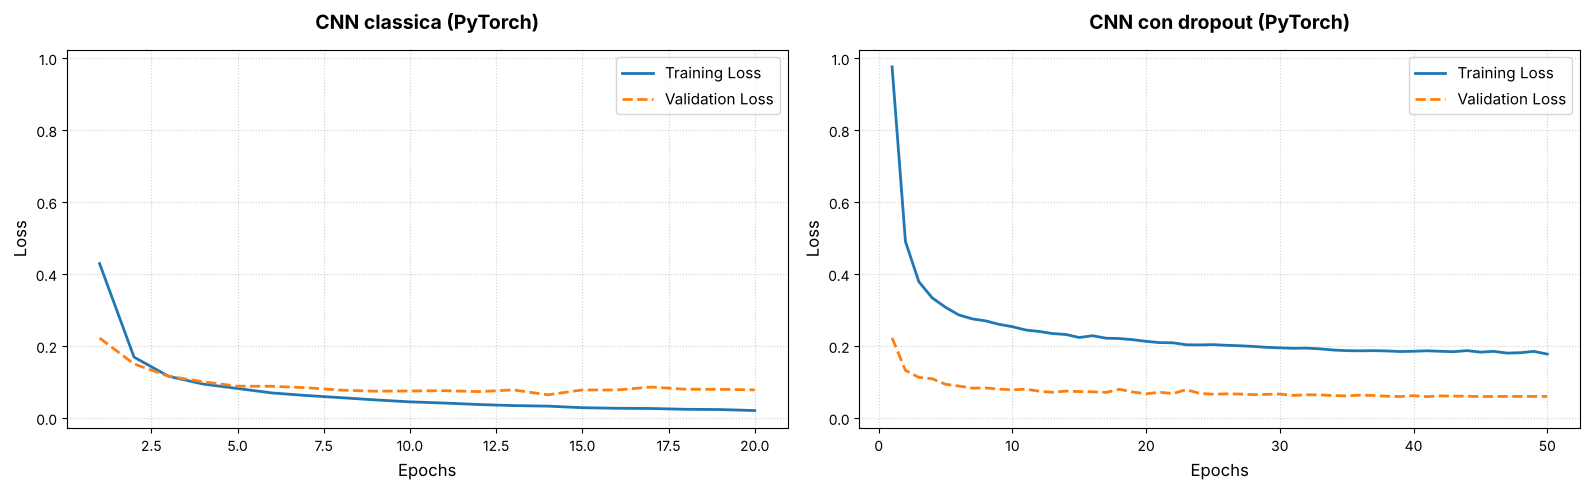

In [8]:
# Visualizzazione grafica delle curve di Training Loss e Validation Loss per entrambe le reti.
# Fondamentale per monitorare l'apprendimento ed escludere fenomeni di Overfitting 
# (quando la rete impara a memoria i dati di training peggiorando sui dati di validazione).

# Funzione di supporto che disegna le due curve di una rete su un asse del grafico.
def plot_losses(ax, loss_train, loss_val, title):
    x_axis_epochs = np.arange(1, len(loss_train) + 1)
    ax.plot(x_axis_epochs, loss_train, label='Training Loss', color='#1f77b4', linewidth=2)
    ax.plot(x_axis_epochs, loss_val, label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Loss', fontsize=12)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(fontsize=11)

# Initialize the plot layout: un pannello per rete, stessa scala sull'asse y per poterle confrontare.
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
plot_losses(axes[0], loss_train_pt, loss_val_pt, 'CNN classica (PyTorch)')
plot_losses(axes[1], loss_train_dropout_pt, loss_val_dropout_pt, 'CNN con dropout (PyTorch)')
axes[1].yaxis.set_tick_params(labelleft=True)

# Display the chart
plt.tight_layout()
# plt.show()
plt.savefig('train_val_loss_pytorch.png', bbox_inches='tight', dpi=200)

## 6. PyTorch Inference

Una volta soddisfatto dal training, valuta l'accuratezza delle reti su un subset completamente nuovo (_testing_). Le reti vengono messe in `model.eval()` prima dell'inferenza.

In [9]:
# Fase di Inferenza (Testing) su dati mai visti durante la fase di addestramento.

# Funzione comune alle due reti: restituisce predizioni ed etichette vere sull'intero test set.
# Nota: le predizioni vengono raccolte in liste e concatenate alla fine. Nella versione precedente gli array
# partivano da np.zeros(N_test) e np.append vi aggiungeva i risultati in coda: i primi N_test elementi
# (tutti zeri, sia in y_pred che in y) risultavano sempre "corretti" e gonfiavano l'accuratezza.
def predict(model, loader):
    # Modalità inferenza: Dropout disattivato.
    model.net.eval()
    y_pred, y = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            output = model.net(inputs)
            y_pred.append(output.detach().numpy().argmax(axis=-1))
            y.append(labels.detach().numpy().argmax(axis=1))
    return np.concatenate(y_pred), np.concatenate(y)

# Perform inference on the test set, with no analog errors
y_pred, y = predict(mnist_cnn_pt, mnist_loader_test)
y_pred_dropout, y_dropout = predict(mnist_cnn_dropout_pt, mnist_loader_test)

# Valuta le prestazioni assolute dei modelli nel dominio digitale "ideale" (esente da rumore analogico),
# calcolando l'accuratezza predittiva finale.

# Evaluate accuracy
accuracy_digitalTrain_digitalTest = np.sum(y == y_pred)/len(y)
accuracy_dropout_digitalTrain_digitalTest = np.sum(y_dropout == y_pred_dropout)/len(y_dropout)
print('===========')
print('No analog errors during training, no analog errors during test')
print('Test accuracy CNN classica:    {:.2f}%'.format(accuracy_digitalTrain_digitalTest*100))
print('Test accuracy CNN con dropout: {:.2f}%'.format(accuracy_dropout_digitalTrain_digitalTest*100))
print('Errori sul test set: {} contro {} (su {} immagini)\n'.format(
    np.sum(y != y_pred), np.sum(y_dropout != y_pred_dropout), N_test))

No analog errors during training, no analog errors during test
Test accuracy CNN classica:    98.13%
Test accuracy CNN con dropout: 98.56%
Errori sul test set: 187 contro 144 (su 10000 immagini)



### 6.1 Robustezza a cifre deformate

L'accuratezza sul test set misura quanto la rete riconosce cifre scritte nello stesso stile di MNIST. Per stimare quanto è affidabile su grafie diverse (come quelle disegnate sulla lavagna) ripetiamo il test su immagini deformate a caso: rotazioni fino a ±20°, zoom fino a ±20% e piccoli spostamenti. Il seed è fisso, quindi entrambe le reti vedono esattamente le stesse deformazioni.

In [10]:
# Test su immagini deformate a caso (stessa funzione random_affine della sezione 5.2, con deformazioni più forti).
def accuracy_deformed(model, loader, seed=123):
    torch.manual_seed(seed)
    model.net.eval()
    correct = 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = random_affine(inputs, rot=20, scale=(0.8, 1.2), shift=0.1, shear=0)
            correct += (model.net(inputs).argmax(dim=1) == labels.argmax(dim=1)).sum().item()
    return correct / len(loader.dataset)

print('Test accuracy su cifre deformate:')
print('CNN classica:    {:.2f}%'.format(accuracy_deformed(mnist_cnn_pt, mnist_loader_test)*100))
print('CNN con dropout: {:.2f}%'.format(accuracy_deformed(mnist_cnn_dropout_pt, mnist_loader_test)*100))

Test accuracy su cifre deformate:


CNN classica:    92.53%


CNN con dropout: 97.20%


In [11]:
# Estrazione e salvataggio dello stato interno dei modelli (pesi e bias) nei file "trained_mnist_cnn.pt" e "trained_mnist_cnn_dropout.pt".
# Consente di ricaricare i modelli pre-addestrati per test futuri senza ripetere il costo computazionale del training.

# Save the models
torch.save(mnist_cnn_pt.net.state_dict(), "trained_mnist_cnn.pt")
torch.save(mnist_cnn_dropout_pt.net.state_dict(), "trained_mnist_cnn_dropout.pt")